$QC)$

In [1]:
import numpy as np
from numba import njit, prange
import matplotlib.pyplot as plt
import scienceplots
import warnings
plt.style.use(["science"])
plt.gcf().set_dpi(400)
warnings.simplefilter('ignore')
# This block of code is designed to set up our imports,
# performs Housekeeping on matplotlib, and stops our code printing useless warnings.

<Figure size 1400x1050 with 0 Axes>

$QC.1)$

In [2]:
@njit(cache=True, fastmath=True,parallel=True)
def Kac_step(state: np.ndarray[tuple[int], int], marked_edges: set[int]) -> np.ndarray[tuple[int], int]:
    '''Implements the dynamics of one step of a Kac ring
        
    Args:
        state: A bitarray storing the state of our Kac ring. Read clockwise from 12 O'clock. (-1 = Black, 1 = White).
        marked_edges: A set storing positions of marked edges.
    
    Returns:
        The state after one step in the same form of our state arg.'''
    
     #  Changes the colour of relevant balls in our Kac ring.
    for i in iter(marked_edges):
       state[i] *= -1
    return np.roll(state, 1) # Rotates all our balls one spot clockwise. 


$QC.2)$

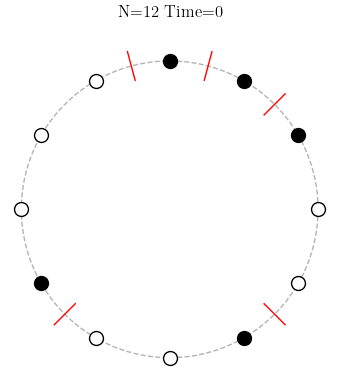

In [3]:
def plot_Kac_ring(state: np.ndarray[tuple[int], int], marked_edges: set[int], N: int,
                   ax: plt.PolarAxes, time: int = 0) -> None:
    '''Plots on our inputted axes a Kac ring.

    Args:
        state: A bitarray storing the state of our Kac ring. Read clockwise from 12 O'clock. (-1 = Black, 1 = White).
        marked_edges: A set storing positions of marked edges.
        N: The Number of balls in our ring.
        ax: The set of axes we plot our Kac ring on.
        time: The time we display in the title.'''
    
    ax.plot(np.linspace(0, 2*np.pi, 240), np.ones(240), '--', lw=1, color='0.7') # Plots the dotty circle.
    for i in range (N):
        θ = np.pi/2 - 2*i*np.pi / N # Finds the polar angle, that we plot our nth ball at.
        ax.plot(θ, 1,'o', color=str(0.5+state[i]/2), markeredgecolor='0', markersize=10)
        θ = np.pi/2 - 2 * (i + 0.5) * np.pi/N # Finds the polar angle, that we plot our nth marked edge at.
        ax.plot([θ, θ], [0.9 ,1.1], color=(1, 0, 0, int(i in marked_edges))) 
    ax.set_axis_off()
    ax.set_title('N=' + str(N) + ' Time=' +  str(time))


def plot_singular_Kac_ring(state: np.ndarray[tuple[int], int], marked_edges: set[int], N: int) -> None:
    '''Plots a Kac ring.

    Args:
        state: A bitarray storing the state of our Kac ring. Read clockwise from 12 O'clock. (-1 = Black, 1 = White).
        marked_edges: A set storing positions of marked edges.
        N: The Number of balls in our ring.'''
    
    fig,ax = plt.subplots(1, 1, figsize= (4, 4), subplot_kw={'projection':'polar'})
    plot_Kac_ring(state, marked_edges, N, ax)
    plt.tight_layout()
    

plot_singular_Kac_ring(np.array([-1, -1, -1, 1, 1, -1, 1, 1, -1, 1, 1, 1]), {0, 1, 4, 7, 11}, 12)

$QC.3)$

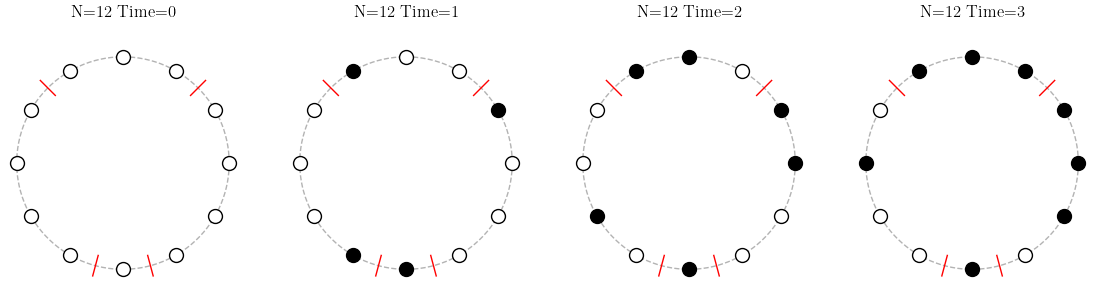

In [4]:
def plot_T_steps(state: np.ndarray[tuple[int], int], marked_edges: set[int], N: int, T: int) -> None:
    ''' Creates a plot of the Kac rings up to time T. 

    Args:
        state: A bitarray storing the state of our Kac ring. Read clockwise from 12 O'clock. (-1 = Black, 1 = White).
        marked_edges: A set storing positions of marked edges.
        N: The Number of balls in our ring.
        T: Number of steps to simulate'''
    
    fig, axs = plt.subplots(1, T+1, figsize=(3.5*(T+1), 3.5*(T+1)), subplot_kw={'projection':'polar'})
    #  Each loop plots then simulates the next Kac_ring.
    for (time, ax) in enumerate(axs):
        plot_Kac_ring(state, marked_edges, N, ax, time)
        state = Kac_step(state, marked_edges)
  

@njit(fastmath=True)
def random_marked_edges(N: int, μ: float) -> set[int]:
    ''' Creates a set of N marked edges with probability μ of each of them being marked.
    
    Args:
        N: The Number of edges we want to potentially mark.
        μ: The chance of an edge being marked
        
    Returns:
        A set of randomly selected marked edges.'''

    marked_edges = set()
    for i in range (N):
        if np.random.binomial(1, μ):
            marked_edges.add(i)    
    return marked_edges 


plot_T_steps(np.ones(12), random_marked_edges(12, 1/3), 12, 3)

$QC.4)$

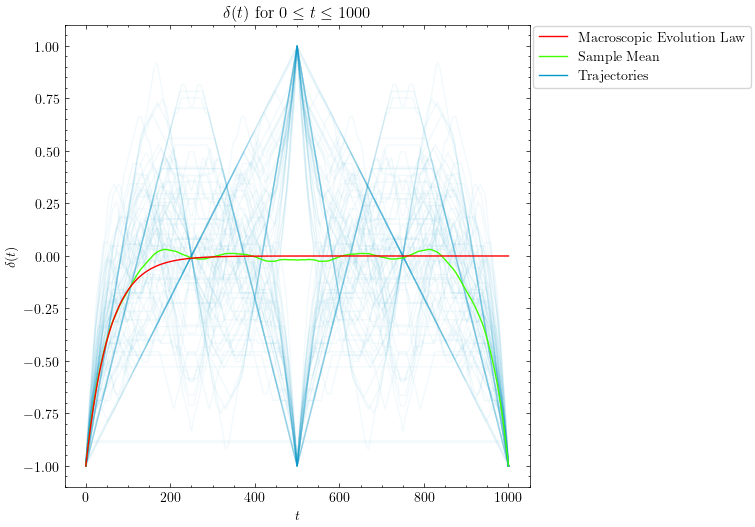

In [5]:
@njit(fastmath=True,parallel=True)
def simulate_ensemble(M: int, N: int, μ: float, T: int) -> np.ndarray[tuple[int, int], float]:
    ''' Simulates an Ensemble
     
    Simulates M Kac rings upto time T.
    All of these have N balls with each edges having a chance μ of being marked. 

    Args:
        M: The number of rings we simulate. 
        N: The number of balls in each ring.
        μ: The chance an edge is marked.
        T: The time we simulate upto.
    
    Returns: 
        A 2d Array where the number at (x,t) is δ(t) for the xth ring in our ensemble.'''
    
    output = np.empty((M, T))

    for i in prange (M):
        state = np.ones(N)
        marked_edges = random_marked_edges(N, μ)
        trajectory = np.empty(T)
        # Applies one step to our ring and then writes -δ(t) to position t of our trajectory.
        for j in range (T):
            trajectory[j] = np.mean(state)
            state = Kac_step(state, marked_edges)
        output[i] = trajectory
    return -output


def plot_Trajectories_Sample_Mean(M: int, N: int, μ: float, T: int,
                                trajectories_plotted: int, ax: plt.Axes) -> None: 
    ''' Plots on ax the sample mean and the desired number of trajectories.
        
    Args:
        M: The number of rings we simulate. 
        N: The number of balls in each ring.
        μ: The chance an edge is marked.
        T: The time we simulate upto.
        trajectories_plotted: The number of trajectories we plot.
        ax: The axes we plot on'''
    
    ensemble = simulate_ensemble(M, N, μ, T) 
    # Plots our trajectories on our axes.    
    for trajectory in enumerate (ensemble[:trajectories_plotted]):
        ax.plot(xs, trajectory[1], color=(0, 0.6, 0.8, 0.05))
    
    ax.plot(0, 0, alpha=1, label='Trajectories', color=(0, 0.6, 0.8)) # Makes a label for our trajectories.
    ax.plot(xs, np.mean(ensemble, axis=0), label='Sample Mean', color=(0.25, 1, 0)) # Plots the sample mean of ensemble.


fig, ax = plt.subplots(1, 1, figsize=(6,6))
# Creates our array for our axes.
xs = np.arange(0, 1001)
plot_Trajectories_Sample_Mean(100, 500, 0.009, 1001, 100, ax) 
def macroscopic_evolution_law(t: int, μ: float=0.009, δ_0: float=-1):
    ''' Applies the macroscopic evolution law at a singular point in time t.
        Args:
            t: The time we're applying macroscopic evolution law to.
            μ: The proportion of edges that are marked.
            δ_0: The colour of the ring at time 0.
        
        Returns: What the macroscopic evolution law predicts for δ at time t.'''
    
    return δ_0*(1-2*μ)**t
vec_macroscopic_evolution_law=np.vectorize(macroscopic_evolution_law)


# Creates the y co-ordinate  values for our macroscopic evolution law line.
ys=vec_macroscopic_evolution_law(xs)
ax.plot(xs, ys, label='Macroscopic Evolution Law', color=(1, 0, 0))
ax.set_title('$\delta(t)$ for $0 \leq t \leq 1000$')
ax.set_xlabel('$t$')
ax.set_ylabel('$\delta(t)$')
fig.legend(bbox_to_anchor=(1.28, 0.89), reverse=True, frameon=True)
plt.show()


$QC.5)$
All our Trajectories have a δ(500) of 1 or -1. This is because all 500 balls have passed all the markers exactly once, so if there's an even number of markers then δ(500)=1 and if an odd number δ(500)=-1

QC.6)

In [ ]:
def V(N: int, μ: float) -> float:
    '''Finds the variance of δ(t).

    Args:
        N: The number of balls in each ring.
        μ: The chance an edge is marked.

    Returns: The Variance.'''
    return 1/(2*μ*(1-μ)*N) - 1/N


# Sets up the 5 plots to put our graphs on.
N=[100, 800, 16000, 32000, 64000]
fig, axs = plt.subplots(1, 5, figsize=(50, 10)) 

for i, ax in enumerate (axs):
    # Sets up the x-axis.
    xs = np.arange((N[i]/2)+1)
    μ = 1/np.sqrt(N[i])
    σ = np.sqrt(V(N[i], N[i]**-0.5))
    # Plots the sample means and 100 trajectories.
    plot_Trajectories_Sample_Mean(1000, N[i], μ, int(N[i]/2)+1, 100, ax)
    ys = macroscopic_evolution_law(xs, μ)
    
    # Plots the Macroscopic evolution law ± σ. 
    ax.plot(xs, ys+σ*np.ones(int(N[i]/2)+1),
            '--', color=(1, 0, 0), label='Macroscopic Evolution Law$+\sigma$')
    ax.plot(xs,ys-σ*np.ones(int(N[i]/2)+1),
            '--', color=(1, 0, 0), label='Macroscopic Evolution Law$-\sigma$')
    ax.plot(xs, ys, label='Macroscopic Evolution Law', color=(1, 0, 0))

    ax.set_ylim(-1.25, 1)
    # Plots the title and legend. 
    ax.set_xlabel('$t$')
    ax.set_ylabel('$\delta(t)$')
    ax.set_title('N=' + str(N[i]) + ' $\delta(t)$ for $0 \leq t \leq$'+ str(int(N[i]/2)))
    ax.set_xlabel('$t$')
    ax.set_ylabel('$\delta(t)$')
    ax.legend(reverse=True, frameon=True)

<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:29: SyntaxWarning: invalid escape sequence '\s'
<>:35: SyntaxWarning: invalid escape sequence '\d'
<>:36: SyntaxWarning: invalid escape sequence '\d'
<>:38: SyntaxWarning: invalid escape sequence '\d'
<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:29: SyntaxWarning: invalid escape sequence '\s'
<>:35: SyntaxWarning: invalid escape sequence '\d'
<>:36: SyntaxWarning: invalid escape sequence '\d'
<>:38: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Leo\AppData\Local\Temp\ipykernel_5636\2115243350.py:27: SyntaxWarning: invalid escape sequence '\s'
  '--', color=(1, 0, 0), label='Macroscopic Evolution Law$+\sigma$')
C:\Users\Leo\AppData\Local\Temp\ipykernel_5636\2115243350.py:29: SyntaxWarning: invalid escape sequence '\s'
  '--', color=(1, 0, 0), label='Macroscopic Evolution Law$-\sigma$')
C:\Users\Leo\AppData\Local\Temp\ipykernel_5636\2115243350.py:35: SyntaxWarning: invalid escape sequence '\d'
  ax.set_ylabel('$\delta(

As we increase N our sample mean gets closer to the macroscopic evolution law, and our variance decrease. Our absolute value of our δ decreases over time so our process has a clear irreversibiliy on a macroscopic level, yet our system is perfectly reversible on a microscopic level so we have demonstrated Loschmidt's paradox

$QC.7)$

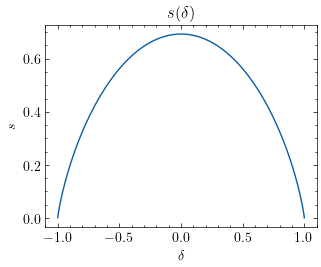

Maximum is at δ=0 with Ω(δ)=0.6931471805599453.


In [6]:
def Ω(δ: float) -> float:
    '''Finds the entropy of the ring given the colour of the ring.
    
    Args:
        δ: The colour of the ring.
    
    Returns: The entropy of our ring.'''
    
    return np.log(2) - ((1+δ)*np.log(1+δ) + (1-δ)*np.log(1-δ))/2
vec_Ω = np.vectorize(Ω)

# Replaces the problematic values (±1) with non problematic values,
# Then maually replace afterwards with the correct ones.
xs = np.arange(-1, 1, 1/1000)
xs[0], xs[-1] = 0, 0
ys = vec_Ω(xs)
xs[0], xs[-1], ys[0], ys[-1] = -1, 1, 0, 0
plt.plot(xs,ys)
ax = plt.gca()
ax.set_title('$s(\delta)$')
ax.set_xlabel('$\delta$')
ax.set_ylabel('$s$')
plt.show()
print(f'Maximum is at δ=0 with Ω(δ)={Ω(0)}.')

$QC.8)$

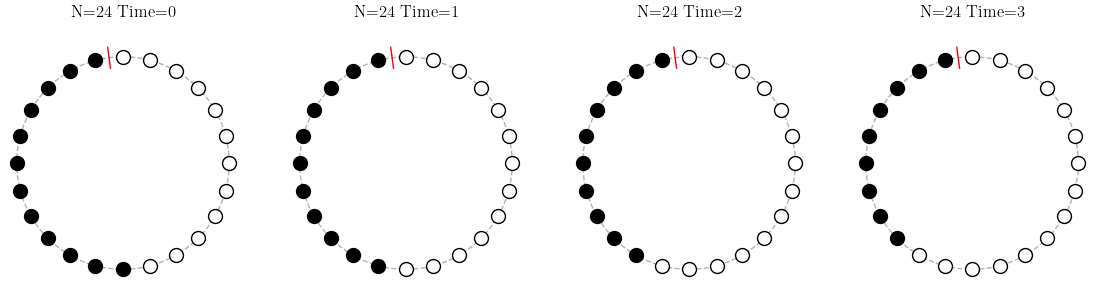

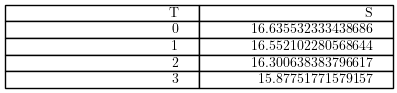

In [7]:
# Sets up our high entropy set up.
state = np.concatenate((np.ones(12),-np.ones(12)))
marked_edges = {23}
N = 24

plot_T_steps(state, marked_edges, N, 3)
fig, ax = plt.subplots(1, 1, figsize=(5, 0.0001)) 
def δ(state: np.ndarray[tuple[int], int], marked_edges: set, T: int):
    '''An iterator to find the colour of a ring over time
    
    Args:
        state: A bitarray storing the state of our Kac ring. Read clockwise from 12 O'clock. (-1 = Black, 1 = White).
        marked_edges: A set storing positions of marked edges.
        T: Number of steps to simulate
    
        Yields: δ(t)'''
    
    for i in range (T+1):
        state = Kac_step(state,marked_edges)
        yield np.mean(state)
# Sets up the table.
T = ['T', '0', '1', '2', '3']
entropy = ['', '', '', '', '']
entropy[1:] = N*vec_Ω(np.fromiter(δ(state,marked_edges,3),float))
entropy[0] = 'S'
ax.table(np.array([T, entropy]).T)
ax.set_axis_off()
plt.show()
